# IIOT — Modelo preditivo: antecipar demanda e risco de estouro do SLA

**Projeto:** Inteligência de Dados Aplicada à Confiabilidade de Ativos (PI II)

A etapa anterior (dashboard) analisou o que **já aconteceu**. Nesta etapa testamos o que os dados permitem **antecipar sobre o futuro**, com três perguntas:

| Parte | Pergunta | Quando a previsão é usada |
|---|---|---|
| **1** | Quantas OS corretivas vão chegar nos próximos meses? | planejamento, meses à frente |
| **2** | Qual a chance de uma OS de SLA de 4 h estourar o prazo? (alvo: `sla_estourado`) | durante o atendimento, para priorizar |
| **3** | É possível antecipar o estouro ou a falha de um ativo *antes* do atendimento? | teste de limites dos dados |

**Cuidados metodológicos em todo o notebook**

- Divisão **por tempo**: treino = passado, teste = futuro (nunca embaralhamos as datas).
- Só usamos variáveis **conhecidas no momento da previsão** (sem vazamento de dados).
- Comparamos sempre com uma referência simples (acaso ou regra básica).

> Como usar no Colab: *Ambiente de execução → Executar tudo*. Os dados são baixados direto do GitHub; não precisa subir arquivos.

## 1. Bibliotecas e carregamento dos dados

In [ ]:
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, r2_score, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
SEED = 42

In [ ]:
URL_BASE = ("https://raw.githubusercontent.com/luisabroocke/"
            "Inteligencia-de-Dados-Aplicada-a-Confiabilidade-de-Ativos/main/data/")

def ler_csv(nome, **kwargs):
    local = Path("data") / nome
    if local.exists():
        return pd.read_csv(local, **kwargs)
    try:
        return pd.read_csv(URL_BASE + nome, **kwargs)
    except Exception:
        # Plano B: se o download falhar, envie o arquivo manualmente no Colab
        print(f"Não foi possível baixar {nome} do GitHub. Selecione o arquivo no seu computador:")
        from google.colab import files
        files.upload()
        return pd.read_csv(nome, **kwargs)

ordens = ler_csv("ordem_servico.csv", low_memory=False)
ativos = ler_csv("ativo.csv", parse_dates=["data_instalacao"])

print("Ordens de serviço:", ordens.shape)
print("Ativos:", ativos.shape)
ordens.head()

Ordens de serviço: (38429, 12)
Ativos: (1200, 9)


,id_ordem_servico,id_chamado,id_ativo,id_tecnico,tipo_os,status_os,data_agendada,data_inicio_real,data_fim_real,limite_sla_solucao,sla_solucao_cumprido,diagnostico_tecnico
0,1,1,1179,2,PREVENTIVA,CANCELADA,2021-01-01 13:00:00,NaN,NaN,2021-01-01 17:00:00,NaN,Cancelado por erro de triagem.
1,2,2,465,1,CORRETIVA,CONCLUÍDA,2021-01-01 17:00:00,2021-01-01 16:57:00,2021-01-01 18:07:00,2021-01-02 17:00:00,True,Intervenção realizada para correção de falha t...
2,3,3,901,5,PREVENTIVA,CONCLUÍDA,2021-01-01 14:00:00,2021-01-01 14:52:00,2021-01-01 18:25:00,2021-01-01 18:00:00,False,Intervenção realizada para correção de falha t...
3,4,4,704,12,CORRETIVA,CONCLUÍDA,2021-01-01 17:00:00,2021-01-01 17:38:00,2021-01-01 21:34:00,2021-01-01 21:00:00,False,Intervenção realizada para correção de falha t...
4,5,5,740,26,PREVENTIVA,CONCLUÍDA,2021-01-01 16:00:00,2021-01-01 16:39:00,2021-01-01 17:50:00,2021-01-01 20:00:00,True,Intervenção realizada para correção de falha t...


## 2. Preparação e definição do alvo

Aplicamos as mesmas regras do dashboard (`app.py`):

- somente OS **corretivas concluídas**;
- `sla_estourado = 1` quando `sla_solucao_cumprido` é falso;
- o prazo contratual (`sla_horas`) é a diferença entre `limite_sla_solucao` e `data_agendada`.

Também criamos aqui o histórico de OS anteriores de cada ativo, **antes** de filtrar as corretivas (assim a contagem considera todo o histórico do equipamento).

In [ ]:
def normalizar(texto):
    texto = unicodedata.normalize("NFKD", str(texto).strip().upper())
    return "".join(c for c in texto if not unicodedata.combining(c))

for col in ["data_agendada", "data_inicio_real", "data_fim_real", "limite_sla_solucao"]:
    ordens[col] = pd.to_datetime(ordens[col], errors="coerce")

ordens["tipo_os"] = ordens["tipo_os"].apply(normalizar)
ordens["status_os"] = ordens["status_os"].apply(normalizar)

# Histórico do ativo: quantas OS ele já tinha ANTES desta (conhecido na abertura)
ordens = ordens.sort_values(["data_agendada", "id_ordem_servico"]).reset_index(drop=True)
ordens["qtd_os_anteriores_ativo"] = ordens.groupby("id_ativo").cumcount()

# Alvo
ordens["sla_estourado"] = (
    ordens["sla_solucao_cumprido"].astype(str).str.lower().eq("false")
).astype(int)

# Medidas de tempo
ordens["sla_horas"] = (ordens["limite_sla_solucao"] - ordens["data_agendada"]).dt.total_seconds() / 3600
ordens["atraso_inicio_min"] = (ordens["data_inicio_real"] - ordens["data_agendada"]).dt.total_seconds() / 60
ordens["tempo_reparo_min"] = (ordens["data_fim_real"] - ordens["data_inicio_real"]).dt.total_seconds() / 60

corretivas = ordens[
    (ordens["tipo_os"] == "CORRETIVA") & (ordens["status_os"] == "CONCLUIDA")
].dropna(subset=["data_inicio_real", "data_fim_real", "sla_horas"]).copy()

print("Corretivas concluídas:", len(corretivas))

Corretivas concluídas: 21267


---
# PARTE 1 — Previsão de demanda de OS corretivas (planejamento com meses de antecedência)

Aqui o objetivo é **antecipar quantas OS corretivas vão chegar** nos próximos meses, para dimensionar equipe e escalas. É uma previsão de futuro de verdade: usa apenas o histórico passado, sem nenhuma informação sobre as OS que ainda vão ocorrer.

### 1.1 A série mensal e sua sazonalidade

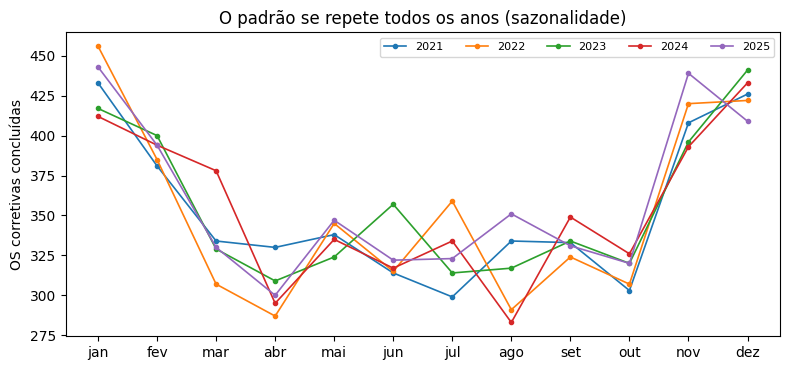

Total por ano: {2021: 4233, 2022: 4218, 2023: 4258, 2024: 4249, 2025: 4309}


In [ ]:
serie = corretivas.set_index("data_agendada").resample("MS").size()
serie.index = serie.index.to_period("M")
demanda = serie.to_frame("os")
demanda["ano"], demanda["mes"] = demanda.index.year, demanda.index.month

pivot = demanda.pivot(index="mes", columns="ano", values="os")

fig, ax = plt.subplots(figsize=(8, 3.8))
for ano in pivot.columns:
    ax.plot(pivot.index, pivot[ano], marker="o", ms=3, lw=1.2, label=str(ano))
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax.set_ylabel("OS corretivas concluídas"); ax.set_title("O padrão se repete todos os anos (sazonalidade)")
ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()

print("Total por ano:", demanda.groupby("ano")["os"].sum().to_dict())

O formato se repete: **pico de novembro a fevereiro** e **vale de abril a outubro**, enquanto o total anual quase não muda. Isso torna a demanda previsível.

### 1.2 Teste de previsão (treino 2021–2024, teste 2025)

Comparamos três métodos simples e explicáveis:

- **Média geral:** prevê sempre a média mensal do treino (ignora a sazonalidade).
- **Mesmo mês do ano anterior:** repete o que aconteceu em 2024.
- **Média sazonal:** média histórica daquele mês do ano (jan = média dos janeiros etc.).

A métrica é o **MAPE** (erro percentual médio): quanto menor, melhor.

In [ ]:
treino_d = demanda[demanda["ano"] < 2025]
teste_d = demanda[demanda["ano"] == 2025]

media_mes = treino_d.groupby("mes")["os"].mean()
ano_anterior = treino_d[treino_d["ano"] == 2024].set_index("mes")["os"]

previsoes = pd.DataFrame({
    "real": teste_d["os"].values,
    "Média geral": treino_d["os"].mean(),
    "Mesmo mês do ano anterior": ano_anterior.reindex(teste_d["mes"]).values,
    "Média sazonal": media_mes.reindex(teste_d["mes"]).values,
}, index=teste_d.index.astype(str))

def mape(real, prev):
    return float(np.mean(np.abs(real - prev) / real) * 100)

comparacao = pd.DataFrame({
    "MAPE (%)": {m: round(mape(previsoes["real"], previsoes[m]), 1)
                 for m in ["Média geral", "Mesmo mês do ano anterior", "Média sazonal"]},
    "Erro médio (OS/mês)": {m: round(float(np.mean(np.abs(previsoes["real"] - previsoes[m]))), 1)
                            for m in ["Média geral", "Mesmo mês do ano anterior", "Média sazonal"]},
})
comparacao

,MAPE (%),Erro médio (OS/mês)
Média geral,10.6,39.5
Mesmo mês do ano anterior,6.2,22.8
Média sazonal,3.5,13.3


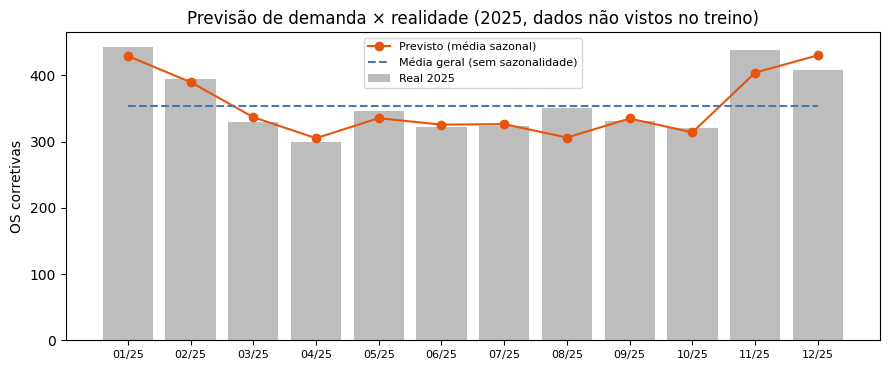

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(previsoes))
ax.bar(x, previsoes["real"], color="#bdbdbd", label="Real 2025")
ax.plot(x, previsoes["Média sazonal"], color="#e6550d", marker="o", label="Previsto (média sazonal)")
ax.plot(x, previsoes["Média geral"], color="#4C78A8", ls="--", label="Média geral (sem sazonalidade)")
ax.set_xticks(x); ax.set_xticklabels([m[-2:] + "/25" for m in previsoes.index], fontsize=8)
ax.set_ylabel("OS corretivas"); ax.set_title("Previsão de demanda × realidade (2025, dados não vistos no treino)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

A média sazonal erra poucos pontos percentuais, bem menos do que ignorar a sazonalidade. Como o teste tem só 12 meses, repetimos o teste em **janela crescente** (prever 2022 com 2021, 2023 com 2021–22, e assim por diante) para ter uma ideia mais estável do erro:

In [ ]:
linhas, erros_pct = [], []
for ano in [2022, 2023, 2024, 2025]:
    tr = demanda[demanda["ano"] < ano]
    te = demanda[demanda["ano"] == ano]
    prev = tr.groupby("mes")["os"].mean().reindex(te["mes"]).values
    ape = np.abs(te["os"].values - prev) / te["os"].values * 100
    erros_pct.extend(ape)
    linhas.append({"ano previsto": ano, "treinou com": "2021" if ano == 2022 else f"2021–{ano - 1}", "MAPE (%)": round(ape.mean(), 1)})

backtest = pd.DataFrame(linhas)
p90 = float(np.percentile(erros_pct, 90))
print(f"Erro percentual em 90% dos meses testados: até {p90:.1f}%")
backtest

Erro percentual em 90% dos meses testados: até 12.2%


,ano previsto,treinou com,MAPE (%)
0,2022,2021,6.0
1,2023,2021–2022,4.3
2,2024,2021–2023,4.9
3,2025,2021–2024,3.5


### 1.3 Projeção de 2026

Usamos a média sazonal de **todo o histórico (2021–2025)**. A faixa informada vem do erro observado nos testes acima (90% dos meses ficaram dentro dela). Também calculamos a carga **por técnico**, que é o dado mais útil para dimensionar escalas.

In [ ]:
media_mes_total = demanda.groupby("mes")["os"].mean()
n_tecnicos = corretivas["id_tecnico"].nunique()
meses_nomes = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]

proj = pd.DataFrame({
    "mês": [f"{m}/26" for m in meses_nomes],
    "previsão de OS": media_mes_total.round(0).astype(int).values,
})
proj["mínimo provável"] = (media_mes_total * (1 - p90 / 100)).round(0).astype(int).values
proj["máximo provável"] = (media_mes_total * (1 + p90 / 100)).round(0).astype(int).values
proj["OS por técnico"] = (media_mes_total / n_tecnicos).round(1).values
proj.to_csv("previsao_demanda_2026.csv", index=False)

print(f"Técnicos com OS corretivas no histórico: {n_tecnicos}")
print(f"Previsão para 2026: {proj['previsão de OS'].sum()} OS corretivas")
proj

Técnicos com OS corretivas no histórico: 30
Previsão para 2026: 4253 OS corretivas


,mês,previsão de OS,mínimo provável,máximo provável,OS por técnico
0,jan/26,432,380,485,14.4
1,fev/26,391,343,438,13.0
2,mar/26,336,295,376,11.2
3,abr/26,304,267,341,10.1
4,mai/26,338,297,379,11.3
5,jun/26,325,285,365,10.8
6,jul/26,326,286,365,10.9
7,ago/26,315,277,354,10.5
8,set/26,334,294,375,11.1
9,out/26,315,277,354,10.5


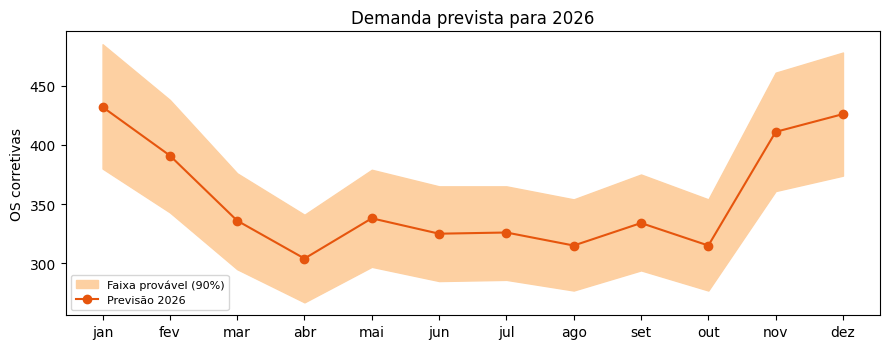

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.fill_between(range(12), proj["mínimo provável"], proj["máximo provável"], color="#fdd0a2", label="Faixa provável (90%)")
ax.plot(range(12), proj["previsão de OS"], color="#e6550d", marker="o", label="Previsão 2026")
ax.set_xticks(range(12)); ax.set_xticklabels(meses_nomes)
ax.set_ylabel("OS corretivas"); ax.set_title("Demanda prevista para 2026")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 1.4 A demanda influencia o estouro do SLA?

Uma pergunta natural: nos meses de pico, o SLA estoura mais? Vamos checar com os dados (somente SLA de 4 h):

In [ ]:
c4 = corretivas[corretivas["sla_horas"].between(3.9, 4.1)].copy()
c4["mes_ref"] = c4["data_agendada"].dt.to_period("M")
mensal_sla = c4.groupby("mes_ref").agg(taxa_estouro=("sla_estourado", "mean"),
                                        atraso_medio=("atraso_inicio_min", "mean"))
mensal_sla["volume"] = serie.reindex(mensal_sla.index)

corr_vol_estouro = mensal_sla["volume"].corr(mensal_sla["taxa_estouro"])
corr_vol_atraso = mensal_sla["volume"].corr(mensal_sla["atraso_medio"])
print(f"Correlação volume mensal × taxa de estouro:  {corr_vol_estouro:.2f}")
print(f"Correlação volume mensal × atraso médio:     {corr_vol_atraso:.2f}")

Correlação volume mensal × taxa de estouro:  0.09
Correlação volume mensal × atraso médio:     0.02


As correlações são próximas de zero: **nos dados disponíveis, o volume de OS não explica o estouro do SLA**. A previsão de demanda serve para planejar a capacidade, mas não deve ser apresentada como um modelo que evita estouros por si só. Quem aponta o risco de estouro é a Parte 2.

---
# PARTE 2 — Risco de estouro do SLA de 4 horas (alerta durante o atendimento)

### 2.0 Em qual grupo vale a pena modelar?

O README já mostrou que **todos os descumprimentos estão no SLA de 4 horas**. Veja a confirmação:

In [ ]:
corretivas["prazo_h"] = corretivas["sla_horas"].round().astype(int)
resumo = corretivas.groupby("prazo_h").agg(
    total_os=("id_ordem_servico", "count"),
    estouros=("sla_estourado", "sum"),
    taxa_estouro=("sla_estourado", "mean"),
)
resumo["taxa_estouro"] = (resumo["taxa_estouro"] * 100).round(1)
resumo

,total_os,estouros,taxa_estouro
prazo_h,,,
4,7248,866,11.9
12,6977,0,0.0
24,7042,0,0.0


Nos prazos de 12 h e 24 h **não há nenhum exemplo da classe "estourou"**, então um modelo não teria o que aprender ali.
Por isso o modelo é treinado apenas nas **OS corretivas com SLA de 4 horas** (o mesmo recorte do dashboard).

In [ ]:
base = corretivas[corretivas["sla_horas"].between(3.9, 4.1)].copy()
base = base.merge(ativos, on="id_ativo", how="left")

# Variáveis conhecidas na ABERTURA da OS
base["hora_agendada"] = base["data_agendada"].dt.hour
base["dia_semana"] = base["data_agendada"].dt.dayofweek
base["mes"] = base["data_agendada"].dt.month
base["idade_ativo_anos"] = (base["data_agendada"] - base["data_instalacao"]).dt.days / 365.25
base["id_tecnico"] = base["id_tecnico"].astype(str)   # tratado como categoria

# Ordem cronológica (importante para a divisão treino/teste)
base = base.sort_values("data_agendada").reset_index(drop=True)

print(f"OS no recorte: {len(base)}  |  estouros: {base['sla_estourado'].sum()}  "
      f"({base['sla_estourado'].mean():.1%})")
print("Período:", base["data_agendada"].min().date(), "→", base["data_agendada"].max().date())

OS no recorte: 7248  |  estouros: 866  (11.9%)
Período: 2021-01-01 → 2025-12-30


## 2.1 Escolha das variáveis (e o cuidado com o vazamento de dados)

A pergunta-chave é: **em que momento o modelo vai ser usado?** Só podemos usar o que já se sabe nesse momento.

| Variável | Quando é conhecida | Usar? |
|---|---|---|
| categoria, fabricante, criticidade do ativo | abertura | ✅ |
| idade do ativo, nº de OS anteriores do ativo | abertura | ✅ |
| técnico responsável, hora/dia/mês agendados | abertura | ✅ |
| **atraso no início** (`data_inicio_real − data_agendada`) | quando o técnico começa o atendimento | ✅ só no **Modelo B** |
| **tempo de reparo**, `data_fim_real`, faturamento, diagnóstico | só depois do atendimento | ❌ **vazamento** |

Faremos duas versões:

- **Modelo A — na abertura da OS:** só variáveis cadastrais e de agendamento.
- **Modelo B — no início do atendimento:** o Modelo A + o atraso no início.

(`especialidade_requerida` foi descartada por ser equivalente à `categoria`; o diagnóstico técnico tem um único texto, sem informação.)

In [ ]:
CAT = ["categoria", "fabricante", "criticidade", "id_tecnico"]
NUM_A = ["hora_agendada", "dia_semana", "mes", "idade_ativo_anos", "qtd_os_anteriores_ativo"]
FEATURES_A = CAT + NUM_A
FEATURES_B = FEATURES_A + ["atraso_inicio_min"]
ALVO = "sla_estourado"

# Divisão POR TEMPO: 80% mais antigo = treino, 20% mais recente = teste
corte = int(len(base) * 0.8)
treino, teste = base.iloc[:corte], base.iloc[corte:]

print(f"Treino: {len(treino)} OS ({treino['data_agendada'].min().date()} → {treino['data_agendada'].max().date()}) "
      f"| estouro {treino[ALVO].mean():.1%}")
print(f"Teste : {len(teste)} OS ({teste['data_agendada'].min().date()} → {teste['data_agendada'].max().date()}) "
      f"| estouro {teste[ALVO].mean():.1%}")

Treino: 5798 OS (2021-01-01 → 2025-01-03) | estouro 11.9%
Teste : 1450 OS (2025-01-03 → 2025-12-30) | estouro 12.1%


> **Por que dividir por tempo e não aleatoriamente?** Na prática o modelo prevê o **futuro** a partir do passado. Uma divisão aleatória misturaria datas e deixaria o teste mais fácil do que a realidade.

## 2.2 Funções de treino e avaliação

Comparamos dois algoritmos:

- **Regressão logística** — simples e explicável (bom ponto de partida).
- **Gradient Boosting** (`HistGradientBoostingClassifier`) — captura relações mais complexas.

Como só ~12% das OS estouram o SLA, **a acurácia engana** (um modelo que sempre diz "não estoura" acerta ~88%). Por isso usamos:

- **AUC-ROC:** capacidade de ordenar quem estoura acima de quem não estoura (0,5 = acaso; 1,0 = perfeito).
- **Average Precision (AP):** qualidade do ranking de risco; a referência é a própria taxa de estouro (~12%).
- **Lift no topo do ranking:** quantas vezes mais estouros existem entre as OS de maior risco do que na média.

In [ ]:
def montar_modelo(tipo, numericas, categoricas):
    if tipo == "logistica":
        pre = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas),
            ("num", StandardScaler(), numericas),
        ])
        clf = LogisticRegression(max_iter=2000)
    else:
        pre = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
            ("num", "passthrough", numericas),
        ])
        clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                             max_iter=150, random_state=SEED)
    return Pipeline([("pre", pre), ("modelo", clf)])


def auc_com_intervalo(y, p, n=300):
    """AUC e intervalo de 95% por bootstrap (mostra a incerteza do resultado)."""
    rng = np.random.default_rng(SEED)
    y, p = np.asarray(y), np.asarray(p)
    aucs = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() != y[idx].max():
            aucs.append(roc_auc_score(y[idx], p[idx]))
    return roc_auc_score(y, p), np.percentile(aucs, 2.5), np.percentile(aucs, 97.5)


def avaliar(nome, tipo, features):
    numericas = [c for c in features if c not in CAT]
    categoricas = [c for c in features if c in CAT]
    modelo = montar_modelo(tipo, numericas, categoricas).fit(treino[features], treino[ALVO])
    p = modelo.predict_proba(teste[features])[:, 1]
    auc, lo, hi = auc_com_intervalo(teste[ALVO], p)
    linha = {
        "modelo": nome,
        "AUC": round(auc, 3),
        "AUC IC95%": f"{lo:.3f} – {hi:.3f}",
        "AP": round(average_precision_score(teste[ALVO], p), 3),
        "AP de referência (taxa base)": round(teste[ALVO].mean(), 3),
    }
    return modelo, p, linha

## 2.3 Modelo A — previsão na abertura da OS

In [ ]:
resultados, modelos, probs = [], {}, {}

for nome, tipo, feats in [
    ("A - Regressão logística", "logistica", FEATURES_A),
    ("A - Gradient Boosting",   "gb",        FEATURES_A),
]:
    modelos[nome], probs[nome], linha = avaliar(nome, tipo, feats)
    resultados.append(linha)

pd.DataFrame(resultados)

,modelo,AUC,AUC IC95%,AP,AP de referência (taxa base)
0,A - Regressão logística,0.527,0.480 – 0.571,0.135,0.121
1,A - Gradient Boosting,0.517,0.472 – 0.558,0.123,0.121


**Leitura do resultado.** Se o AUC fica muito perto de **0,5** e o intervalo de confiança inclui 0,5, o modelo **não consegue distinguir** as OS de maior risco usando só dados da abertura.

Isso é coerente com a análise do dashboard: fabricante e categoria não explicavam os estouros. Vamos conferir olhando as taxas de estouro por grupo:

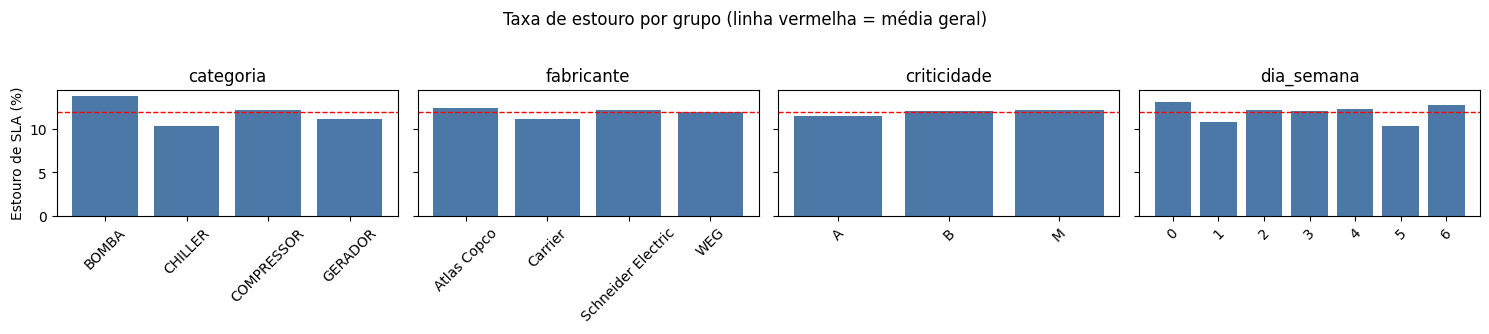

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, col in zip(axes, ["categoria", "fabricante", "criticidade", "dia_semana"]):
    taxa = base.groupby(col)[ALVO].mean() * 100
    ax.bar(taxa.index.astype(str), taxa.values, color="#4C78A8")
    ax.axhline(base[ALVO].mean() * 100, color="red", ls="--", lw=1)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Estouro de SLA (%)")
fig.suptitle("Taxa de estouro por grupo (linha vermelha = média geral)", y=1.03)
plt.tight_layout(); plt.show()

Os grupos ficam todos próximos da média: **com os dados cadastrais e de agendamento disponíveis, não há informação suficiente para prever o estouro na abertura da OS.** Esse é um resultado válido e deve constar na apresentação — ele mostra que o problema não está *no ativo*, e sim *no processo de atendimento*.

## 2.4 Modelo B — previsão no início do atendimento

Na análise do dashboard o fator mais forte era o **atraso entre o horário agendado e o início real**. Esse dado passa a existir no momento em que o técnico começa (ou deveria ter começado) o atendimento — ainda **antes** do reparo terminar, então **não é vazamento** e permite agir durante o atendimento.

In [ ]:
for nome, tipo, feats in [
    ("B - Regressão logística", "logistica", FEATURES_B),
    ("B - Gradient Boosting",   "gb",        FEATURES_B),
]:
    modelos[nome], probs[nome], linha = avaliar(nome, tipo, feats)
    resultados.append(linha)

# Regra simples de comparação: quanto maior o atraso, maior o risco
auc_r, lo_r, hi_r = auc_com_intervalo(teste[ALVO], teste["atraso_inicio_min"])
resultados.append({
    "modelo": "Regra simples (só o atraso)", "AUC": round(auc_r, 3),
    "AUC IC95%": f"{lo_r:.3f} – {hi_r:.3f}",
    "AP": round(average_precision_score(teste[ALVO], teste["atraso_inicio_min"]), 3),
    "AP de referência (taxa base)": round(teste[ALVO].mean(), 3),
})
tabela = pd.DataFrame(resultados)
tabela

,modelo,AUC,AUC IC95%,AP,AP de referência (taxa base)
0,A - Regressão logística,0.527,0.480 – 0.571,0.135,0.121
1,A - Gradient Boosting,0.517,0.472 – 0.558,0.123,0.121
2,B - Regressão logística,0.781,0.751 – 0.811,0.286,0.121
3,B - Gradient Boosting,0.774,0.748 – 0.805,0.284,0.121
4,Regra simples (só o atraso),0.785,0.759 – 0.815,0.294,0.121


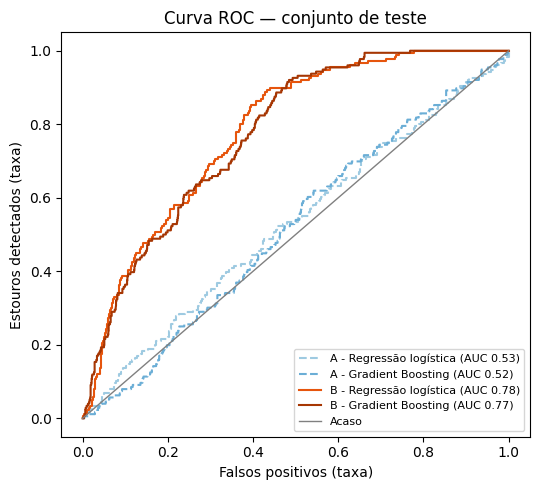

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 5))
estilos = {
    "A - Regressão logística": ("#9ecae1", "--"),
    "A - Gradient Boosting":   ("#6baed6", "--"),
    "B - Regressão logística": ("#e6550d", "-"),
    "B - Gradient Boosting":   ("#a63603", "-"),
}
for nome, (cor, ls) in estilos.items():
    fpr, tpr, _ = roc_curve(teste[ALVO], probs[nome])
    ax.plot(fpr, tpr, color=cor, ls=ls, label=f"{nome} (AUC {roc_auc_score(teste[ALVO], probs[nome]):.2f})")
ax.plot([0, 1], [0, 1], color="gray", lw=1, label="Acaso")
ax.set_xlabel("Falsos positivos (taxa)"); ax.set_ylabel("Estouros detectados (taxa)")
ax.set_title("Curva ROC — conjunto de teste"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

O Modelo B melhora de forma clara em relação ao A (de ~0,52 para ~0,78 de AUC).

**Ponto de atenção:** a *regra simples* (ordenar as OS apenas pelo atraso no início) alcança praticamente o mesmo AUC que os modelos. Ou seja, **o ganho vem quase todo do atraso no início**; as demais variáveis não acrescentam informação relevante. O que o modelo entrega a mais é traduzir o atraso em uma **probabilidade** (por exemplo, "34% de risco"), que facilita criar faixas de risco. O gráfico abaixo mostra **por que** o atraso pesa tanto: a taxa de estouro cresce de forma quase contínua com ele.

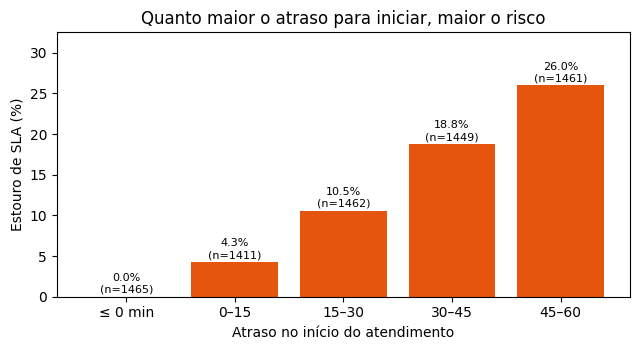

In [ ]:
faixas = pd.cut(base["atraso_inicio_min"], [-16, 0, 15, 30, 45, 61],
                labels=["≤ 0 min", "0–15", "15–30", "30–45", "45–60"])
taxa_faixa = base.groupby(faixas, observed=True)[ALVO].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(taxa_faixa.index.astype(str), taxa_faixa["mean"] * 100, color="#e6550d")
for i, (m, n) in enumerate(zip(taxa_faixa["mean"], taxa_faixa["count"])):
    ax.text(i, m * 100 + 0.5, f"{m:.1%}\n(n={n})", ha="center", fontsize=8)
ax.set_ylabel("Estouro de SLA (%)"); ax.set_xlabel("Atraso no início do atendimento")
ax.set_ylim(0, taxa_faixa["mean"].max() * 100 * 1.25)
ax.set_title("Quanto maior o atraso para iniciar, maior o risco")
plt.tight_layout(); plt.show()

### Importância das variáveis (Modelo B)

Medimos quanto o AUC **cai** no teste quando embaralhamos cada variável (*permutation importance*). Quanto maior a queda, mais o modelo depende dela.

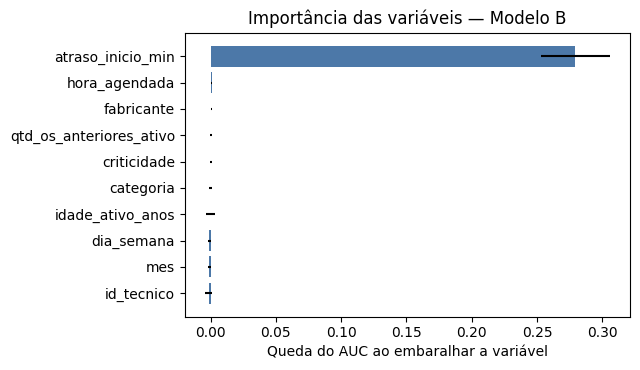

In [ ]:
nome_final = "B - Gradient Boosting"
imp = permutation_importance(
    modelos[nome_final], teste[FEATURES_B], teste[ALVO],
    scoring="roc_auc", n_repeats=10, random_state=SEED
)
imp_df = (pd.DataFrame({"variavel": FEATURES_B, "queda_auc": imp.importances_mean,
                        "desvio": imp.importances_std})
          .sort_values("queda_auc"))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(imp_df["variavel"], imp_df["queda_auc"], xerr=imp_df["desvio"], color="#4C78A8")
ax.set_xlabel("Queda do AUC ao embaralhar a variável")
ax.set_title("Importância das variáveis — Modelo B")
plt.tight_layout(); plt.show()

## 2.5 Demonstração do vazamento de dados

Para mostrar por que a escolha das variáveis importa, treinamos um modelo que usa também o **tempo de reparo** — informação que só existe quando o atendimento termina:

In [ ]:
feats_vazamento = FEATURES_B + ["tempo_reparo_min"]
numericas = [c for c in feats_vazamento if c not in CAT]
m_vaz = montar_modelo("gb", numericas, CAT).fit(treino[feats_vazamento], treino[ALVO])
p_vaz = m_vaz.predict_proba(teste[feats_vazamento])[:, 1]
print(f"AUC com vazamento (usa o tempo de reparo): {roc_auc_score(teste[ALVO], p_vaz):.3f}")

AUC com vazamento (usa o tempo de reparo): 1.000


O AUC fica **praticamente perfeito** — mas é uma ilusão. O estouro é *definido* por `início + reparo > limite do SLA`, então o modelo só está refazendo a conta depois que tudo aconteceu. Esse modelo **não serve** para prevenir nada. Por isso ele fica fora da solução final.

## 2.6 Como o risco apoia a priorização

Ordenamos as OS do teste por risco estimado e verificamos quantos estouros reais ficam concentrados no topo da fila.

In [ ]:
def tabela_lift(y, p, cortes=(0.05, 0.10, 0.20, 0.30, 0.50)):
    df = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)}).sort_values("p", ascending=False)
    taxa_base, total_estouros = df["y"].mean(), df["y"].sum()
    linhas = []
    for c in cortes:
        topo = df.head(int(len(df) * c))
        linhas.append({
            "OS priorizadas (% da fila)": f"{c:.0%}",
            "nº de OS": len(topo),
            "estouros nessa fatia": int(topo["y"].sum()),
            "taxa de estouro na fatia": f"{topo['y'].mean():.1%}",
            "% dos estouros capturados": f"{topo['y'].sum() / total_estouros:.1%}",
            "lift (x a média)": round(topo["y"].mean() / taxa_base, 2),
        })
    return pd.DataFrame(linhas)

print("MODELO B (gradient boosting) — taxa média de estouro no teste:", f"{teste[ALVO].mean():.1%}")
tabela_lift(teste[ALVO], probs["B - Gradient Boosting"])

MODELO B (gradient boosting) — taxa média de estouro no teste: 12.1%


,OS priorizadas (% da fila),nº de OS,estouros nessa fatia,taxa de estouro na fatia,% dos estouros capturados,lift (x a média)
0,5%,72,29,40.3%,16.5%,3.32
1,10%,145,51,35.2%,29.0%,2.90
2,20%,290,85,29.3%,48.3%,2.41
3,30%,435,109,25.1%,61.9%,2.06
4,50%,725,153,21.1%,86.9%,1.74


In [ ]:
print("MODELO A (gradient boosting) — para comparação:")
tabela_lift(teste[ALVO], probs["A - Gradient Boosting"])

MODELO A (gradient boosting) — para comparação:


,OS priorizadas (% da fila),nº de OS,estouros nessa fatia,taxa de estouro na fatia,% dos estouros capturados,lift (x a média)
0,5%,72,7,9.7%,4.0%,0.80
1,10%,145,14,9.7%,8.0%,0.80
2,20%,290,35,12.1%,19.9%,0.99
3,30%,435,53,12.2%,30.1%,1.00
4,50%,725,93,12.8%,52.8%,1.06


### Faixas de risco

Transformamos a probabilidade em faixas simples, que a equipe de operação consegue usar no dia a dia. A coluna *taxa observada* mostra se a faixa faz sentido (deve crescer de Baixo para Alto).

In [ ]:
risco = teste[["id_ordem_servico", "atraso_inicio_min", ALVO]].copy()
risco["prob_estouro"] = probs["B - Gradient Boosting"]
risco["faixa_risco"] = pd.cut(risco["prob_estouro"], [0, 0.10, 0.25, 1.0],
                              labels=["Baixo (<10%)", "Médio (10–25%)", "Alto (>25%)"],
                              include_lowest=True)
faixas_risco = risco.groupby("faixa_risco", observed=False).agg(
    n_os=("id_ordem_servico", "count"),
    estouros=(ALVO, "sum"),
    taxa_observada=(ALVO, "mean"),
    prob_media_prevista=("prob_estouro", "mean"),
)
faixas_risco[["taxa_observada", "prob_media_prevista"]] = (
    faixas_risco[["taxa_observada", "prob_media_prevista"]].round(3)
)
faixas_risco

,n_os,estouros,taxa_observada,prob_media_prevista
faixa_risco,,,,
Baixo (<10%),747,28,0.037,0.037
Médio (10–25%),597,110,0.184,0.154
Alto (>25%),106,38,0.358,0.300


In [ ]:
# Exemplo: as 10 OS de maior risco do período de teste
(risco.sort_values("prob_estouro", ascending=False)
      .head(10)
      .assign(prob_estouro=lambda d: d["prob_estouro"].round(3))
      .rename(columns={"sla_estourado": "estourou_de_fato"}))

,id_ordem_servico,atraso_inicio_min,estourou_de_fato,prob_estouro,faixa_risco
5846,30998,60.0,0,0.474,Alto (>25%)
6022,31958,60.0,0,0.437,Alto (>25%)
6063,32228,60.0,0,0.410,Alto (>25%)
6396,33848,60.0,0,0.390,Alto (>25%)
7048,37282,60.0,1,0.387,Alto (>25%)
6520,34500,60.0,0,0.387,Alto (>25%)
6207,32989,59.0,0,0.386,Alto (>25%)
5876,31200,59.0,0,0.385,Alto (>25%)
7095,37511,60.0,1,0.385,Alto (>25%)
6196,32931,56.0,0,0.384,Alto (>25%)


## 2.7 Salvando o resultado

Salvamos o modelo treinado, a tabela de métricas e as previsões do teste. Esses arquivos podem ser versionados no GitHub e usados para criar uma aba de risco no PyDash.

> O modelo final é treinado novamente com **todos os dados** antes de ser salvo (o teste serviu apenas para medir o desempenho).

In [ ]:
import joblib

modelo_final = montar_modelo("gb", [c for c in FEATURES_B if c not in CAT], CAT)
modelo_final.fit(base[FEATURES_B], base[ALVO])

joblib.dump({"modelo": modelo_final, "features": FEATURES_B}, "modelo_risco_sla.joblib")
tabela.to_csv("metricas_modelo.csv", index=False)
risco.to_csv("previsoes_teste.csv", index=False)
print("Arquivos salvos: modelo_risco_sla.joblib, metricas_modelo.csv, previsoes_teste.csv")

# No Colab, descomente para baixar os arquivos:
# from google.colab import files
# for f in ["modelo_risco_sla.joblib", "metricas_modelo.csv", "previsoes_teste.csv"]:
#     files.download(f)

Arquivos salvos: modelo_risco_sla.joblib, metricas_modelo.csv, previsoes_teste.csv


In [ ]:
# Exemplo de uso: risco de uma OS nova, no momento em que o atendimento começa
nova_os = pd.DataFrame([{
    "categoria": "BOMBA", "fabricante": "WEG", "criticidade": "A", "id_tecnico": "12",
    "hora_agendada": 15, "dia_semana": 2, "mes": 6, "idade_ativo_anos": 4.0,
    "qtd_os_anteriores_ativo": 10,
}])
for atraso in [0, 15, 30, 45, 60]:
    nova_os["atraso_inicio_min"] = atraso
    prob = modelo_final.predict_proba(nova_os[FEATURES_B])[0, 1]
    print(f"Atraso de {atraso:>2} min no início → risco estimado de estourar o SLA: {prob:.1%}")

Atraso de  0 min no início → risco estimado de estourar o SLA: 0.0%
Atraso de 15 min no início → risco estimado de estourar o SLA: 5.9%
Atraso de 30 min no início → risco estimado de estourar o SLA: 16.0%
Atraso de 45 min no início → risco estimado de estourar o SLA: 19.7%
Atraso de 60 min no início → risco estimado de estourar o SLA: 34.6%


---
# PARTE 3 — Tentativas de previsão antecipada que os dados não sustentam

Um modelo preditivo só é confiável se testamos também o que **não funciona**. Aqui tentamos antecipar eventos **antes do atendimento começar**, com o máximo de informação disponível. Todos os testes usam treino no passado e teste no futuro.

### 3.1 Estouro do SLA na abertura da OS, com carga do técnico e histórico do ativo

Além das variáveis da Parte 2, criamos: quantas OS o técnico já tinha no dia, o total de OS no dia e quantos estouros o ativo já teve antes.

In [ ]:
todas = ordens.copy()
todas["dia"] = todas["data_agendada"].dt.date
todas["carga_tecnico_antes"] = todas.groupby(["id_tecnico", "dia"]).cumcount()
todas["carga_tecnico_dia"] = todas.groupby(["id_tecnico", "dia"])["id_ordem_servico"].transform("count")
todas["os_total_dia"] = todas.groupby("dia")["id_ordem_servico"].transform("count")
todas["estouros_previos_ativo"] = todas.groupby("id_ativo")["sla_estourado"].cumsum() - todas["sla_estourado"]

EXTRAS = ["carga_tecnico_antes", "carga_tecnico_dia", "os_total_dia", "estouros_previos_ativo"]
base_ext = base.merge(todas[["id_ordem_servico"] + EXTRAS], on="id_ordem_servico", how="left")
base_ext = base_ext.sort_values("data_agendada").reset_index(drop=True)
tr_e, te_e = base_ext.iloc[:corte], base_ext.iloc[corte:]

FEATURES_A2 = FEATURES_A + EXTRAS
num_a2 = [c for c in FEATURES_A2 if c not in CAT]
m_a2 = montar_modelo("gb", num_a2, CAT).fit(tr_e[FEATURES_A2], tr_e[ALVO])
p_a2 = m_a2.predict_proba(te_e[FEATURES_A2])[:, 1]
auc_a2, lo_a2, hi_a2 = auc_com_intervalo(te_e[ALVO], p_a2)
print(f"AUC (abertura + carga do técnico + histórico do ativo): {auc_a2:.3f}  (IC95% {lo_a2:.3f} – {hi_a2:.3f})")

AUC (abertura + carga do técnico + histórico do ativo): 0.485  (IC95% 0.431 – 0.534)


### 3.2 É possível prever o atraso de início ou a duração do reparo?

Se conseguíssemos prever esses dois tempos na abertura, o estouro seria previsível. Usamos o **R²** (1 = perfeito; 0 = igual a chutar a média; negativo = pior que chutar a média).

In [ ]:
def r2_teste(alvo):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
        ("num", "passthrough", num_a2),
    ])
    reg = Pipeline([("pre", pre), ("modelo", HistGradientBoostingRegressor(
        max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED))])
    reg.fit(tr_e[FEATURES_A2], tr_e[alvo])
    return r2_score(te_e[alvo], reg.predict(te_e[FEATURES_A2]))

r2_atraso = r2_teste("atraso_inicio_min")
r2_reparo = r2_teste("tempo_reparo_min")
print(f"R² para prever o atraso no início:        {r2_atraso:.3f}")
print(f"R² para prever a duração do reparo:       {r2_reparo:.3f}")

R² para prever o atraso no início:        -0.033
R² para prever a duração do reparo:       -0.043


### 3.3 Prever qual ativo terá falha no mês seguinte

Esse é o objetivo clássico da manutenção preditiva. Montamos uma tabela **ativo × mês** e tentamos prever se o ativo terá alguma OS corretiva no mês seguinte, usando o histórico recente de falhas (últimos 1, 3, 6 e 12 meses), idade, categoria, fabricante e criticidade.

In [ ]:
meses = pd.period_range("2021-01", "2025-12", freq="M")
painel = pd.MultiIndex.from_product([ativos["id_ativo"], meses], names=["id_ativo", "mes_ref"]).to_frame(index=False)

contagem = (corretivas.assign(mes_ref=corretivas["data_agendada"].dt.to_period("M"))
            .groupby(["id_ativo", "mes_ref"]).size().rename("n").reset_index())
painel = painel.merge(contagem, how="left", on=["id_ativo", "mes_ref"]).fillna({"n": 0})
painel = painel.sort_values(["id_ativo", "mes_ref"]).reset_index(drop=True)

g = painel.groupby("id_ativo")["n"]
painel["falha_prox_mes"] = (g.shift(-1) > 0).astype(int)
painel["falhas_mes"] = painel["n"]
for janela in (3, 6, 12):
    painel[f"falhas_{janela}m"] = g.transform(lambda s, j=janela: s.rolling(j, min_periods=1).sum())
painel["falhas_acum"] = g.cumsum()

painel = painel.merge(ativos[["id_ativo", "categoria", "fabricante", "criticidade", "data_instalacao"]], on="id_ativo")
painel["idade_anos"] = (painel["mes_ref"].dt.to_timestamp() - painel["data_instalacao"]).dt.days / 365.25
painel["mes_do_ano"] = painel["mes_ref"].dt.month
painel = painel[painel["mes_ref"] < pd.Period("2025-12", freq="M")]   # último mês não tem "próximo mês"

num_p = ["falhas_mes", "falhas_3m", "falhas_6m", "falhas_12m", "falhas_acum", "idade_anos", "mes_do_ano"]
cat_p = ["categoria", "fabricante", "criticidade"]
eh_treino = painel["mes_ref"] < pd.Period("2025-01", freq="M")

pre_p = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_p),
    ("num", "passthrough", num_p),
])
mod_p = Pipeline([("pre", pre_p), ("modelo", HistGradientBoostingClassifier(
    max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED))])
mod_p.fit(painel.loc[eh_treino, num_p + cat_p], painel.loc[eh_treino, "falha_prox_mes"])
p_p = mod_p.predict_proba(painel.loc[~eh_treino, num_p + cat_p])[:, 1]
y_p = painel.loc[~eh_treino, "falha_prox_mes"].values

auc_p, lo_p, hi_p = auc_com_intervalo(y_p, p_p)
print(f"Taxa de ativos com falha no mês seguinte (teste): {y_p.mean():.1%}")
print(f"AUC: {auc_p:.3f}  (IC95% {lo_p:.3f} – {hi_p:.3f})")

Taxa de ativos com falha no mês seguinte (teste): 25.3%
AUC: 0.517  (IC95% 0.505 – 0.529)


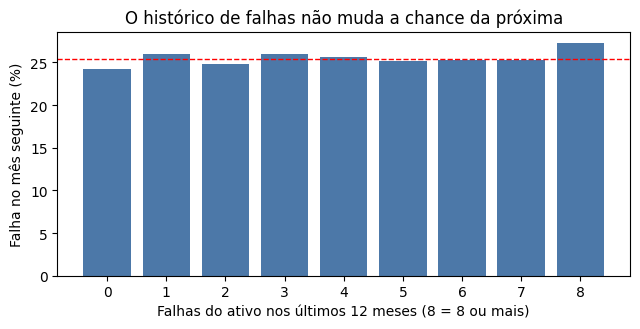

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
taxa_hist = painel.groupby(painel["falhas_12m"].clip(upper=8))["falha_prox_mes"].mean() * 100
ax.bar(taxa_hist.index.astype(int).astype(str), taxa_hist.values, color="#4C78A8")
ax.axhline(painel["falha_prox_mes"].mean() * 100, color="red", ls="--", lw=1)
ax.set_xlabel("Falhas do ativo nos últimos 12 meses (8 = 8 ou mais)")
ax.set_ylabel("Falha no mês seguinte (%)")
ax.set_title("O histórico de falhas não muda a chance da próxima")
plt.tight_layout(); plt.show()

### 3.4 Resumo dos testes

In [ ]:
auc_a_gb = float(tabela.loc[tabela["modelo"] == "A - Gradient Boosting", "AUC"].iloc[0])
resumo_testes = pd.DataFrame([
    {"tentativa": "Estouro de SLA na abertura (Parte 2, Modelo A)", "métrica": "AUC", "resultado": round(auc_a_gb, 3), "referência (acaso)": 0.5},
    {"tentativa": "Estouro de SLA na abertura + carga do técnico + histórico", "métrica": "AUC", "resultado": round(auc_a2, 3), "referência (acaso)": 0.5},
    {"tentativa": "Prever o atraso no início", "métrica": "R²", "resultado": round(r2_atraso, 3), "referência (acaso)": 0.0},
    {"tentativa": "Prever a duração do reparo", "métrica": "R²", "resultado": round(r2_reparo, 3), "referência (acaso)": 0.0},
    {"tentativa": "Falha do ativo no mês seguinte", "métrica": "AUC", "resultado": round(auc_p, 3), "referência (acaso)": 0.5},
])
resumo_testes.to_csv("testes_previsao_antecipada.csv", index=False)
resumo_testes

,tentativa,métrica,resultado,referência (acaso)
0,"Estouro de SLA na abertura (Parte 2, Modelo A)",AUC,0.517,0.5
1,Estouro de SLA na abertura + carga do técnico ...,AUC,0.485,0.5
2,Prever o atraso no início,R²,-0.033,0.0
3,Prever a duração do reparo,R²,-0.043,0.0
4,Falha do ativo no mês seguinte,AUC,0.517,0.5


Todas as tentativas ficam no nível do acaso (AUC próximo de 0,5; R² próximo de zero ou negativo). Na falha do ativo o AUC chega a ~0,52: estatisticamente acima de 0,5 por causa do grande número de linhas, mas sem utilidade prática. **Com as colunas disponíveis, não é possível antecipar o estouro do SLA nem a falha do ativo antes do atendimento.** O que é previsível é a **demanda agregada** (Parte 1) e o **risco durante o atendimento** (Parte 2).


### 3.5 As demais bases do projeto trazem informação nova?

Além de `ordem_servico`, `ativo` e `faturamento_os`, o projeto tem outras bases: `chamado`, `tecnico_especialidade`, `resposta_checklist`, `leitura_horimetro` (telemetria dos 50 dispositivos IoT) e `cliente`. Testamos se alguma delas ajuda a antecipar o atraso, o reparo, o estouro ou a falha:

- **Chamado:** a descrição do defeito é a mesma em todos os chamados; testamos a *antecedência* entre abrir o chamado e o horário agendado.
- **Técnico:** se a especialidade do técnico coincide com a exigida pelo ativo.
- **Checklist:** itens não conformes (só existe *depois* do atendimento, então serve apenas para ver se há relação).
- **Telemetria:** temperatura, vibração e horas acumuladas preveem uma corretiva nos próximos 7 ou 30 dias? (treino até 2024, teste em 2025)

A base `cliente` só tem dados cadastrais e não entra no teste.

In [ ]:
# Lê as demais bases do projeto (a função ler_csv já foi definida no início do notebook)
os2 = ler_csv("ordem_servico.csv", parse_dates=["data_agendada", "data_inicio_real", "data_fim_real", "limite_sla_solucao"], low_memory=False)
cham = ler_csv("chamado.csv", parse_dates=["data_abertura"])
atv = ler_csv("ativo.csv")
tec = ler_csv("tecnico_especialidade.csv")
chk = ler_csv("resposta_checklist.csv")
hor = ler_csv("leitura_horimetro.csv", parse_dates=["timestamp_leitura"])
disp = ler_csv("dispositivo_iot.csv")

d = (os2.merge(cham[["id_chamado", "data_abertura"]], on="id_chamado")
        .merge(atv[["id_ativo", "especialidade_requerida"]], on="id_ativo")
        .merge(tec, on="id_tecnico"))
d = d[(d.tipo_os == "CORRETIVA") & (d.status_os == "CONCLUÍDA")].copy()
d["prazo_h"] = ((d.limite_sla_solucao - d.data_agendada).dt.total_seconds() / 3600).round()
d["atraso_min"] = (d.data_inicio_real - d.data_agendada).dt.total_seconds() / 60
d["reparo_h"] = (d.data_fim_real - d.data_inicio_real).dt.total_seconds() / 3600
d["estouro"] = (~d.sla_solucao_cumprido.astype(bool)).astype(int)
d["antecedencia_h"] = (d.data_agendada - d.data_abertura).dt.total_seconds() / 3600
d["espec_ok"] = d.nome_especialidade == d.especialidade_requerida

print("Descrição do defeito distinta nos chamados:", cham["descricao_defeito"].nunique() if "descricao_defeito" in cham else "n/d")
print("OS em que a especialidade do técnico é a exigida pelo ativo: %.1f%%" % (100 * d.espec_ok.mean()))
print("Antecedência do chamado (h): corr. com o atraso = %.3f | com o reparo = %.3f"
      % (d.antecedencia_h.corr(d.atraso_min), d.antecedencia_h.corr(d.reparo_h)))
q4 = d[d.prazo_h == 4]
print("Taxa de estouro (SLA 4 h) por faixa de antecedência:")
print((q4.groupby(pd.qcut(q4.antecedencia_h, 5, duplicates="drop"), observed=True).estouro.mean() * 100).round(1).to_string())

nc = chk[chk.resposta_status != "CONFORME"].groupby("id_ordem_servico").size().rename("n_nao_conforme")
d = d.merge(nc, on="id_ordem_servico", how="left").fillna({"n_nao_conforme": 0})
print("\nChecklist (só existe após o atendimento): corr. itens não conformes x reparo = %.3f | x estouro = %.3f"
      % (d.n_nao_conforme.corr(d.reparo_h), d.n_nao_conforme.corr(d.estouro)))

# Telemetria (50 dispositivos): leituras diárias de temperatura/vibração prevêem uma corretiva nos próximos 7 ou 30 dias?
h = hor.merge(disp[["id_dispositivo_iot", "id_ativo"]], on="id_dispositivo_iot").sort_values(["id_ativo", "timestamp_leitura"])
h["dia"] = h.timestamp_leitura.dt.normalize()
dias_corr = d.assign(dia=d.data_agendada.dt.normalize()).groupby("id_ativo").dia.apply(lambda s: np.sort(s.values))
for H in (7, 30):
    alvo = []
    for a, dia in zip(h.id_ativo.values, h.dia.values):
        arr = dias_corr.get(a)
        if arr is None:
            alvo.append(0); continue
        i = np.searchsorted(arr, dia, side="right")
        alvo.append(int(i < len(arr) and (arr[i] - dia) <= np.timedelta64(H, "D")))
    h[f"y{H}"] = alvo
for col in ["temperatura_celsius", "vibracao_mm_s"]:
    h[col + "_m7"] = h.groupby("id_ativo")[col].transform(lambda s: s.rolling(7, min_periods=1).mean())
    h[col + "_dif"] = h.groupby("id_ativo")[col].diff()
FH = ["horas_acumuladas", "temperatura_celsius", "vibracao_mm_s", "temperatura_celsius_m7",
      "vibracao_mm_s_m7", "temperatura_celsius_dif", "vibracao_mm_s_dif"]
tr_h, te_h = h[h.dia < "2025-01-01"], h[h.dia >= "2025-01-01"]
print()
for H in (7, 30):
    mh = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.05, random_state=0).fit(tr_h[FH], tr_h[f"y{H}"])
    auc_h = roc_auc_score(te_h[f"y{H}"], mh.predict_proba(te_h[FH])[:, 1])
    print(f"Telemetria -> corretiva em {H} dias: AUC = {auc_h:.3f} (acaso = 0,5; taxa no teste = {te_h[f'y{H}'].mean():.1%})")


Não foi possível baixar chamado.csv do GitHub. Selecione o arquivo no seu computador:


Saving chamado.csv to chamado.csv
Não foi possível baixar tecnico_especialidade.csv do GitHub. Selecione o arquivo no seu computador:


Saving tecnico_especialidade.csv to tecnico_especialidade.csv
Não foi possível baixar resposta_checklist.csv do GitHub. Selecione o arquivo no seu computador:


Saving resposta_checklist.csv to resposta_checklist.csv
Não foi possível baixar leitura_horimetro.csv do GitHub. Selecione o arquivo no seu computador:


Saving leitura_horimetro.csv to leitura_horimetro.csv
Não foi possível baixar dispositivo_iot.csv do GitHub. Selecione o arquivo no seu computador:


Saving dispositivo_iot.csv to dispositivo_iot.csv
Descrição do defeito distinta nos chamados: 1
OS em que a especialidade do técnico é a exigida pelo ativo: 100.0%
Antecedência do chamado (h): corr. com o atraso = 0.007 | com o reparo = 0.005
Taxa de estouro (SLA 4 h) por faixa de antecedência:
antecedencia_h
(0.999, 4.0]    11.7
(4.0, 5.0]      12.2
(5.0, 6.0]      13.1
(6.0, 8.0]      11.2
(8.0, 10.0]     12.2

Checklist (só existe após o atendimento): corr. itens não conformes x reparo = 0.010 | x estouro = -0.001

Telemetria -> corretiva em 7 dias: AUC = 0.501 (acaso = 0,5; taxa no teste = 6.0%)
Telemetria -> corretiva em 30 dias: AUC = 0.500 (acaso = 0,5; taxa no teste = 22.7%)


**Leitura.** Nenhuma das bases acrescenta informação: a especialidade do técnico sempre coincide com a exigida (não há variação para testar), a antecedência do chamado e o checklist têm correlação próxima de zero com o atraso, o reparo e o estouro, e a telemetria fica no nível do acaso (AUC ≈ 0,50). Isso reforça o resultado da Parte 3: com os dados atuais, o que acontece antes do atendimento não antecipa o estouro.

---
# Conclusões e limitações

**O que o projeto entrega: três camadas de antecipação**

| Camada | Horizonte | Resultado |
|---|---|---|
| **Parte 1 — Demanda de OS corretivas** | meses à frente | Previsão sazonal com erro de poucos pontos percentuais; projeção de 2026 com faixa provável e OS por técnico. |
| **Parte 2 — Risco de estouro do SLA de 4 h** | horas à frente, no início do atendimento | O risco sobe de forma clara com o atraso para iniciar; o modelo gera probabilidade e faixas Baixo / Médio / Alto para priorizar. |
| **Parte 3 — Limites dos dados** | antes do atendimento | Estouro de SLA e falha de ativo não são previsíveis com as colunas atuais. |

**Pontos de atenção**

- O modelo da Parte 2 **não supera a regra simples** "quanto maior o atraso, maior o risco". O valor dele está em fornecer a probabilidade e as faixas de risco.
- O volume de OS **não explica** o estouro do SLA; a previsão de demanda apoia o planejamento de capacidade, não a prevenção direta de estouros.
- Os testes da Parte 3 mostram que o atraso e a duração do reparo não dependem de nada do que se sabe na abertura da OS. Para avançar seria preciso **coletar mais informação na abertura**: tipo de falha, peças necessárias, complexidade estimada, disponibilidade de técnicos.
- Os resultados são associações estatísticas e **não provam causalidade**; reduzir o atraso não garante, sozinho, o cumprimento do SLA.
